In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import DBSCAN

from sklearn.decomposition import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing    import PreProcessData
from utils.plotFigures      import linePlot, lineAndScatterPlot, scatterPlot3D
from clustering.clusteringTimeSeries import ClusteringTimeSeries

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = StandardScaler() #MinMaxScaler() 
preData.normalizeData(scaler);

## Split time series graph

In [3]:
linePlot(df, x='tiempo', y='corriente(A)', color='trajectory')

# Clustering

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'pca':    DBSCAN(eps=0.9, min_samples=60), #, n_jobs=-1),
                       'umap':   DBSCAN(eps=2.6, min_samples=60), #, n_jobs=-1),
                       'pacmap': DBSCAN(eps=3,   min_samples=60)} #, n_jobs=-1)} 

dimReductionModels  = {'pca':    PCA(n_components=3),
                       'umap':   umap.UMAP(n_components=3),
                       'pacmap': pacmap.PaCMAP(n_components=3)}

In [5]:
Clusters = ClusteringTimeSeries(data                = preData.crusher1, 
                                dataNormalized      = dfManipulableVar, 
                                clusteringModels    = clusteringModels, 
                                dimReductionModels  = dimReductionModels)

In [6]:
# Clusters are calculated
Clusters.getResults()

100%|██████████| 6/6 [01:08<00:00, 11.37s/it]


{'1':       corriente(A)  velocidad(rpm)  Potencia(kW)  posicion_poste(%)  \
 0        -0.202616        1.098129      0.452471          -1.096752   
 1         0.993333        1.098178      0.482328          -1.081015   
 2         0.663406        1.098159      0.826030          -1.065278   
 3         0.822041        1.098178      1.517555          -1.049541   
 4         0.076791        1.098178     -0.570062          -1.090242   
 ...            ...             ...           ...                ...   
 4769     -0.823317        1.098296     -0.940125          -1.438079   
 4770     -0.814638        1.098295     -0.922059          -1.438079   
 4771     -0.805959        1.098297     -0.964573          -1.438079   
 4772     -0.797280        1.098179     -0.886161          -1.438079   
 4773     -0.788601        1.098180     -1.000396          -1.438079   
 
       presion_estanque_aire(bar)  Eje_piñón_aceite(%)  \
 0                      -1.513978            -4.916432   
 1           

## Graphs of the results

### Comparison of clusters by dimensionality reduction algorithm

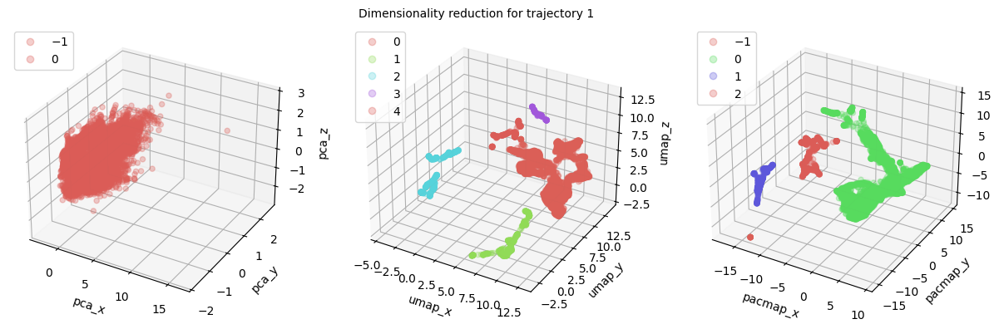

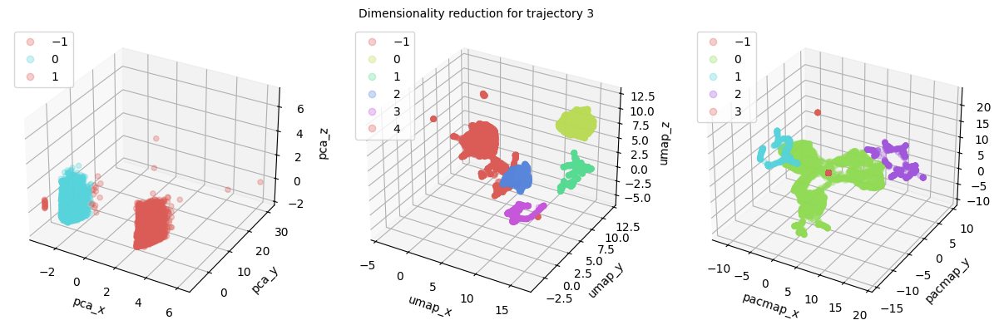

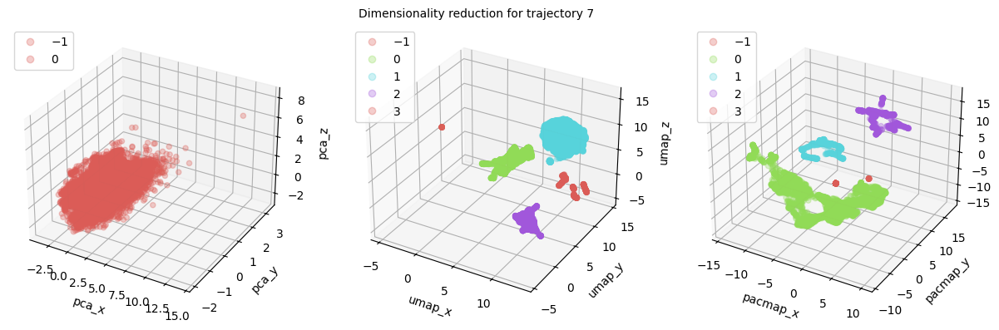

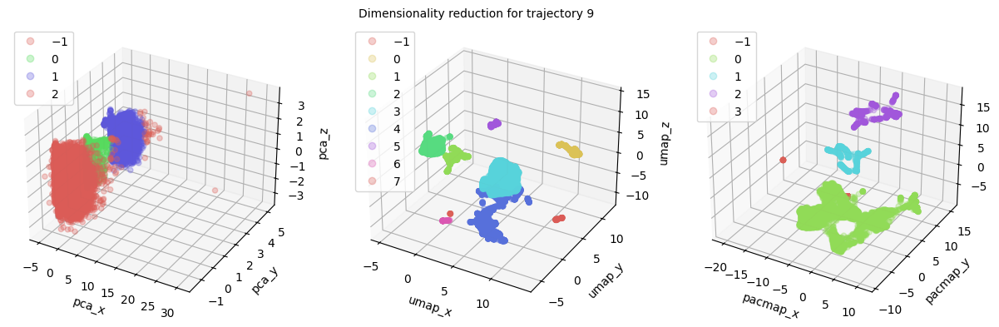

In [7]:
numberFigures = 4
Clusters.subplotsScatter3D(numberFigures)

### Clusters in embedding space

In [8]:
Clusters.plotFigure('scatter3D', 
                    idxTrajectory   = 5, 
                    idxVariable     = 10, 
                    algorithm       = 'pacmap')

### Time series colored by clusters

In [9]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 1, 
                    idxVariable     = 0, 
                    algorithm       = 'pacmap')

# Clusters Comparison

In [10]:
dfSimilarclusters = Clusters.getSimilarClusters(algorithm = 'pacmap', 
                                                threshold = 5)

In [11]:
idxGroupCluster = 1
scatterPlot3D(data  = dfSimilarclusters[dfSimilarclusters['group']==idxGroupCluster], 
              x     = 'pacmap_x', 
              y     = 'pacmap_y', 
              z     = 'pacmap_z', 
              color = 'label')

In [12]:
Clusters.trajectories

array(['1', '3', '7', '9', '11', '15', '17', '19', '21', '23', '25', '27',
       '29', '37', '39', '41', '45', '49', '51', '55', '61', '63', '65',
       '67', '71'], dtype=object)

In [13]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory=2, 
#                     idxVariable=0, 
#                     algorithm='pacmap')

In [14]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory=0, 
#                     idxVariable=0, 
#                     algorithm='pacmap')